In [14]:

import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Locate the project root
project_root = Path.cwd()

if not (project_root / "config/data_paths.json").exists():
    project_root = project_root.parent

# Load the configured dataset location
with open(project_root / "config/data_paths.json") as f:
    config = json.load(f)

dataset_root = Path(config["dataset_root"])

# Identify all processed CSV files
processed_files = sorted(
    dataset_root.glob("*/P*/Processed Files/*.csv")
)

# Collect session-level fatigue information
records = []

for file in processed_files:
    data = pd.read_csv(
        file,
        usecols=[
            "Physical Fatigue - Initial",
            "Physical Fatigue - Final"
        ],
        nrows=1
    )

    records.append({
        "Task": file.relative_to(dataset_root).parts[0],
        "Participant": file.relative_to(dataset_root).parts[1],
        "Session": file.stem.split("_P")[0],
        "Initial Fatigue": data.iloc[0]["Physical Fatigue - Initial"],
        "Final Fatigue": data.iloc[0]["Physical Fatigue - Final"]
    })

scores_df = pd.DataFrame(records)

print("Dataset found:", dataset_root.is_dir())
print("Processed CSV files:", len(processed_files))
print("Participants:", scores_df["Participant"].nunique())

display(scores_df.head())


Dataset found: True
Processed CSV files: 469
Participants: 38


,Task,Participant,Session,Initial Fatigue,Final Fatigue
0,Composite,P1,Final_Rest,7,3
1,Composite,P1,Initial_Rest,1,1
2,Composite,P1,Rep1,1,3
3,Composite,P1,Rep2,3,5
4,Composite,P1,Rep3,5,6



### Fatigue Class Distribution


Activity sessions: 335


Fatigue Level,Low,Moderate,High
Task,,,
Composite,62,81,37
Wire Harness,41,64,50


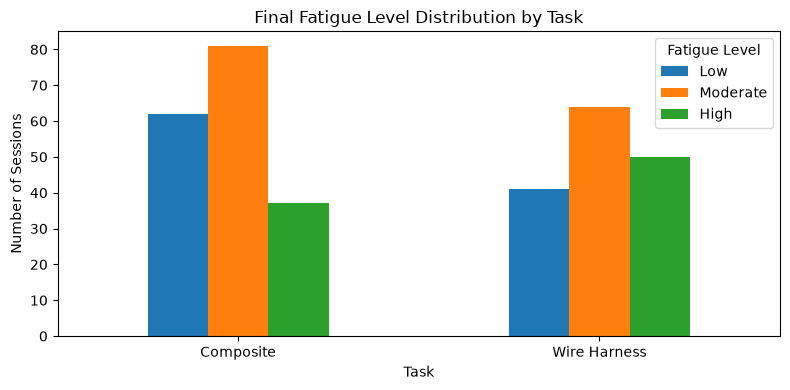

In [15]:

# Select the five physical activity repetitions
activity_sessions = ["Rep1", "Rep2", "Rep3", "Rep4", "Rep5"]

activity_df = scores_df[
    scores_df["Session"].isin(activity_sessions)
].copy()

# Convert final fatigue scores into three classes
# 0-3 = Low, 4-6 = Moderate, 7-10 = High
fatigue_levels = ["Low", "Moderate", "High"]

activity_df["Fatigue Level"] = pd.cut(
    activity_df["Final Fatigue"],
    bins=[-1, 3, 6, 10],
    labels=fatigue_levels
)

# Count fatigue classes separately for each task
class_distribution = pd.crosstab(
    activity_df["Task"],
    activity_df["Fatigue Level"]
).reindex(
    index=["Composite", "Wire Harness"],
    columns=fatigue_levels,
    fill_value=0
)

print("Activity sessions:", len(activity_df))
display(class_distribution)

# Visualize the fatigue class distribution
class_distribution.plot(
    kind="bar",
    figsize=(8, 4),
    rot=0
)

plt.title("Final Fatigue Level Distribution by Task")
plt.xlabel("Task")
plt.ylabel("Number of Sessions")
plt.legend(title="Fatigue Level")
plt.tight_layout()
plt.show()



### Sensor Patterns by Fatigue Level


,Median HR,Median Temperature
Fatigue Level,,
Low,100.15,34.64
Moderate,107.35,34.34
High,112.85,34.77


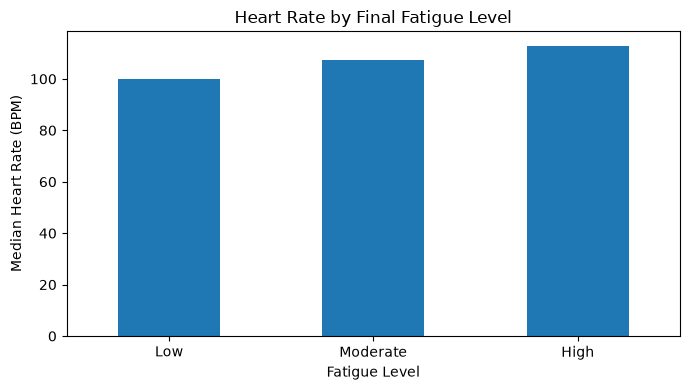

In [16]:

# Select physiological sensor columns
sensor_columns = ["HR_Processed", "Temperature"]

# Store sensor summaries for each activity session
sensor_records = []

for file in processed_files:
    session = file.stem.split("_P")[0]

    # Skip rest sessions
    if session not in activity_sessions:
        continue

    data = pd.read_csv(file, usecols=sensor_columns)

    # Exclude special heart-rate codes and extreme values
    # These are preliminary screening limits for EDA only
    hr = data["HR_Processed"]
    valid_hr = hr.where((hr > 0) & (hr <= 220))

    sensor_records.append({
        "Task": file.relative_to(dataset_root).parts[0],
        "Participant": file.relative_to(dataset_root).parts[1],
        "Session": session,
        "Median HR": valid_hr.median(),
        "Median Temperature": data["Temperature"].median()
    })

# Combine sensor summaries with the session fatigue labels
sensor_eda_df = activity_df.merge(
    pd.DataFrame(sensor_records),
    on=["Task", "Participant", "Session"],
    how="inner"
)

# Compare typical sensor values across fatigue levels
sensor_summary = (
    sensor_eda_df.groupby("Fatigue Level", observed=True)[
        ["Median HR", "Median Temperature"]
    ]
    .median()
    .reindex(fatigue_levels)
    .round(2)
)

display(sensor_summary)

# Visualize the heart-rate pattern across fatigue levels
sensor_summary["Median HR"].plot(
    kind="bar",
    figsize=(7, 4),
    rot=0
)

plt.title("Heart Rate by Final Fatigue Level")
plt.xlabel("Fatigue Level")
plt.ylabel("Median Heart Rate (BPM)")
plt.tight_layout()
plt.show()



### HRV and Motion Sensor Patterns


In [17]:

import numpy as np

# Select chest-related HRV and motion sensor columns
motion_columns = [
    "HRV",
    "acc_X", "acc_Y", "acc_Z",
    "IMU_5_gx_dps_", "IMU_5_gy_dps_", "IMU_5_gz_dps_"
]

motion_records = []

# Analyze only the physical activity sessions
for file in processed_files:
    session = file.stem.split("_P")[0]

    if session not in activity_sessions:
        continue

    data = pd.read_csv(file, usecols=motion_columns)

    # Screen out extreme HRV values for exploratory analysis
    # These limits are not final preprocessing rules
    hrv = data["HRV"].where(
        data["HRV"].between(0, 10000)
    )

    # Calculate accelerometer magnitude
    acceleration = np.sqrt(
        data["acc_X"]**2 +
        data["acc_Y"]**2 +
        data["acc_Z"]**2
    )

    # Calculate gyroscope magnitude from chest IMU
    gyroscope = np.sqrt(
        data["IMU_5_gx_dps_"]**2 +
        data["IMU_5_gy_dps_"]**2 +
        data["IMU_5_gz_dps_"]**2
    )

    motion_records.append({
        "Task": file.relative_to(dataset_root).parts[0],
        "Participant": file.relative_to(dataset_root).parts[1],
        "Session": session,
        "Median HRV": hrv.median(),
        "Acceleration STD": acceleration.std(),
        "Median Gyroscope": gyroscope.median()
    })

# Match sensor statistics with fatigue labels
motion_eda_df = activity_df.merge(
    pd.DataFrame(motion_records),
    on=["Task", "Participant", "Session"],
    how="inner"
)

# Compare motion and HRV features across fatigue levels
motion_summary = (
    motion_eda_df.groupby("Fatigue Level", observed=True)[
        ["Median HRV", "Acceleration STD", "Median Gyroscope"]
    ]
    .median()
    .reindex(fatigue_levels)
    .round(2)
)

display(motion_summary)


,Median HRV,Acceleration STD,Median Gyroscope
Fatigue Level,,,
Low,58.20,0.07,8.70
Moderate,62.05,0.07,8.26
High,68.94,0.07,7.25



### All Sensor Inputs by Fatigue Level


In [18]:

# Combine physiological and motion features from previous EDA results
combined_sensor_df = sensor_eda_df.merge(
    motion_eda_df[
        ["Task", "Participant", "Session",
         "Median HRV", "Acceleration STD", "Median Gyroscope"]
    ],
    on=["Task", "Participant", "Session"],
    how="inner",
    validate="one_to_one"
)

# Select all five sensor features
feature_columns = [
    "Median HR",
    "Median HRV",
    "Median Temperature",
    "Acceleration STD",
    "Median Gyroscope"
]

# Calculate typical session-level values for each fatigue class
all_sensor_summary = (
    combined_sensor_df
    .groupby("Fatigue Level", observed=True)[feature_columns]
    .median()
    .reindex(fatigue_levels)
    .round(2)
)

# Rename columns for easier reading
all_sensor_summary = all_sensor_summary.rename(
    columns={"Median Temperature": "Median Skin Temperature"}
)

display(all_sensor_summary)


,Median HR,Median HRV,Median Skin Temperature,Acceleration STD,Median Gyroscope
Fatigue Level,,,,,
Low,100.15,58.20,34.64,0.07,8.70
Moderate,107.35,62.05,34.34,0.07,8.26
High,112.85,68.94,34.77,0.07,7.25



### Sensor Feature Outlier Detection


In [19]:

# Select the five sensor features
features = [
    "Median HR",
    "Median HRV",
    "Median Temperature",
    "Acceleration STD",
    "Median Gyroscope"
]

# Store the outlier analysis results
outlier_results = []

for feature in features:
    # Calculate the first and third quartiles
    Q1 = combined_sensor_df[feature].quantile(0.25)
    Q3 = combined_sensor_df[feature].quantile(0.75)

    # Calculate the Interquartile Range
    IQR = Q3 - Q1

    # Define statistical outlier boundaries
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify values outside the boundaries
    outliers = (
        (combined_sensor_df[feature] < lower_bound) |
        (combined_sensor_df[feature] > upper_bound)
    )

    # Record the number and percentage of outliers
    outlier_results.append({
        "Feature": feature,
        "Lower Bound": round(lower_bound, 2),
        "Upper Bound": round(upper_bound, 2),
        "Outlier Count": outliers.sum(),
        "Outlier (%)": round(outliers.mean() * 100, 2)
    })

# Create the outlier summary table
outlier_summary = pd.DataFrame(outlier_results)

print("Total activity sessions:", len(combined_sensor_df))

display(outlier_summary)


Total activity sessions: 335


,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier (%)
0,Median HR,69.35,142.55,18,5.37
1,Median HRV,-154.92,358.87,53,15.82
2,Median Temperature,30.64,38.25,12,3.58
3,Acceleration STD,-25.50,42.62,5,1.49
4,Median Gyroscope,-4.16,22.92,2,0.60



### Mean Sensor Values by Fatigue Level


In [20]:

# Calculate mean values for all five sensor inputs
mean_records = []

sensor_columns = [
    "HR_Processed", "HRV", "Temperature",
    "acc_X", "acc_Y", "acc_Z",
    "IMU_5_gx_dps_", "IMU_5_gy_dps_", "IMU_5_gz_dps_"
]

for file in processed_files:
    session = file.stem.split("_P")[0]

    # Include only physical activity sessions
    if session not in activity_sessions:
        continue

    data = pd.read_csv(file, usecols=sensor_columns)

    # Exclude invalid heart-rate codes
    hr = data["HR_Processed"].where(
        data["HR_Processed"].between(1, 220)
    )

    # Apply preliminary HRV screening
    hrv = data["HRV"].where(
        data["HRV"].between(0, 10000)
    )

    # Calculate acceleration magnitude
    acceleration = np.sqrt(
        data["acc_X"]**2 +
        data["acc_Y"]**2 +
        data["acc_Z"]**2
    )

    # Calculate gyroscope magnitude
    gyroscope = np.sqrt(
        data["IMU_5_gx_dps_"]**2 +
        data["IMU_5_gy_dps_"]**2 +
        data["IMU_5_gz_dps_"]**2
    )

    # Calculate session-level mean features
    mean_records.append({
        "Task": file.relative_to(dataset_root).parts[0],
        "Participant": file.relative_to(dataset_root).parts[1],
        "Session": session,
        "Mean HR": hr.mean(),
        "Mean HRV": hrv.mean(),
        "Mean Skin Temperature": data["Temperature"].mean(),
        "Mean Acceleration": acceleration.mean(),
        "Mean Gyroscope": gyroscope.mean()
    })

# Combine features with session-level fatigue labels
mean_sensor_df = activity_df.merge(
    pd.DataFrame(mean_records),
    on=["Task", "Participant", "Session"],
    how="inner",
    validate="one_to_one"
)

# Calculate the mean of session-level features for each fatigue class
mean_sensor_summary = (
    mean_sensor_df.groupby("Fatigue Level", observed=True)[
        [
            "Mean HR",
            "Mean HRV",
            "Mean Skin Temperature",
            "Mean Acceleration",
            "Mean Gyroscope"
        ]
    ]
    .mean()
    .reindex(fatigue_levels)
    .round(2)
)

display(mean_sensor_summary)


,Mean HR,Mean HRV,Mean Skin Temperature,Mean Acceleration,Mean Gyroscope
Fatigue Level,,,,,
Low,101.48,384.56,34.51,6.25,17.48
Moderate,108.04,427.00,34.22,9.40,16.19
High,113.85,441.78,34.54,7.45,16.51



### Mean Sensor Values by Repetition


In [21]:

import numpy as np

# Select the five sensor inputs from the dataset
sensor_columns = [
    "HR_Processed", "HRV", "Temperature",
    "acc_X", "acc_Y", "acc_Z",
    "IMU_5_gx_dps_", "IMU_5_gy_dps_", "IMU_5_gz_dps_"
]

mean_records = []

# Calculate mean sensor values for each repetition
for file in processed_files:
    session = file.stem.split("_P")[0]

    # Include only Rep1 to Rep5
    if session not in activity_sessions:
        continue

    data = pd.read_csv(file, usecols=sensor_columns)

    # Exclude invalid HR codes and screen extreme values
    hr = data["HR_Processed"].where(
        data["HR_Processed"].between(1, 220)
    )

    # Apply preliminary HRV screening for EDA
    hrv = data["HRV"].where(
        data["HRV"].between(0, 10000)
    )

    # Calculate acceleration magnitude
    acceleration = np.sqrt(
        data["acc_X"]**2 +
        data["acc_Y"]**2 +
        data["acc_Z"]**2
    )

    # Calculate gyroscope magnitude
    gyroscope = np.sqrt(
        data["IMU_5_gx_dps_"]**2 +
        data["IMU_5_gy_dps_"]**2 +
        data["IMU_5_gz_dps_"]**2
    )

    # Calculate mean values within each participant's session
    mean_records.append({
        "Task": file.relative_to(dataset_root).parts[0],
        "Participant": file.relative_to(dataset_root).parts[1],
        "Session": session,
        "Mean HR": hr.mean(),
        "Mean HRV": hrv.mean(),
        "Mean Skin Temperature": data["Temperature"].mean(),
        "Mean Acceleration": acceleration.mean(),
        "Mean Gyroscope": gyroscope.mean()
    })

# Match mean sensor values with fatigue classes
mean_sensor_df = activity_df.merge(
    pd.DataFrame(mean_records),
    on=["Task", "Participant", "Session"],
    how="inner",
    validate="one_to_one"
)

# Define the five sensor features
feature_columns = [
    "Mean HR",
    "Mean HRV",
    "Mean Skin Temperature",
    "Mean Acceleration",
    "Mean Gyroscope"
]

# Generate five separate tables for Rep1 to Rep5
for rep in activity_sessions:

    rep_data = mean_sensor_df[
        mean_sensor_df["Session"] == rep
    ]

    # Calculate the average of session means for each fatigue level
    rep_summary = (
        rep_data.groupby("Fatigue Level", observed=True)[feature_columns]
        .mean()
        .reindex(fatigue_levels)
        .round(2)
    )

    print(f"\n{rep} - Mean Sensor Values by Fatigue Level")
    display(rep_summary)



Rep1 - Mean Sensor Values by Fatigue Level


,Mean HR,Mean HRV,Mean Skin Temperature,Mean Acceleration,Mean Gyroscope
Fatigue Level,,,,,
Low,98.76,604.49,33.78,6.56,15.67
Moderate,106.69,622.58,33.13,8.57,14.62
High,98.02,345.21,33.99,0.50,15.06



Rep2 - Mean Sensor Values by Fatigue Level


,Mean HR,Mean HRV,Mean Skin Temperature,Mean Acceleration,Mean Gyroscope
Fatigue Level,,,,,
Low,100.71,423.20,34.41,5.72,17.09
Moderate,106.03,438.12,34.03,8.89,16.25
High,108.00,285.44,34.20,7.88,15.49



Rep3 - Mean Sensor Values by Fatigue Level


,Mean HR,Mean HRV,Mean Skin Temperature,Mean Acceleration,Mean Gyroscope
Fatigue Level,,,,,
Low,102.87,242.64,35.09,5.33,17.90
Moderate,110.95,310.76,34.24,10.48,16.64
High,111.72,329.60,34.81,7.73,15.83



Rep4 - Mean Sensor Values by Fatigue Level


,Mean HR,Mean HRV,Mean Skin Temperature,Mean Acceleration,Mean Gyroscope
Fatigue Level,,,,,
Low,104.56,165.12,35.19,6.16,19.23
Moderate,108.58,415.48,34.71,9.82,15.89
High,114.36,473.94,34.79,7.27,17.74



Rep5 - Mean Sensor Values by Fatigue Level


,Mean HR,Mean HRV,Mean Skin Temperature,Mean Acceleration,Mean Gyroscope
Fatigue Level,,,,,
Low,104.73,148.95,35.15,7.60,20.60
Moderate,108.08,372.91,35.03,9.16,17.55
High,119.52,559.23,34.36,8.48,16.53



### Median Sensor Values by Repetition


In [22]:

import numpy as np

# Select the five sensor inputs
sensor_columns = [
    "HR_Processed", "HRV", "Temperature",
    "acc_X", "acc_Y", "acc_Z",
    "IMU_5_gx_dps_", "IMU_5_gy_dps_", "IMU_5_gz_dps_"
]

median_records = []

# Calculate median sensor values for each repetition
for file in processed_files:
    session = file.stem.split("_P")[0]

    # Include only Rep1 to Rep5
    if session not in activity_sessions:
        continue

    data = pd.read_csv(file, usecols=sensor_columns)

    # Exclude invalid HR codes and apply preliminary screening
    hr = data["HR_Processed"].where(
        data["HR_Processed"].between(1, 220)
    )

    # Screen extreme HRV values for exploratory analysis
    hrv = data["HRV"].where(
        data["HRV"].between(0, 10000)
    )

    # Calculate acceleration magnitude
    acceleration = np.sqrt(
        data["acc_X"]**2 +
        data["acc_Y"]**2 +
        data["acc_Z"]**2
    )

    # Calculate gyroscope magnitude
    gyroscope = np.sqrt(
        data["IMU_5_gx_dps_"]**2 +
        data["IMU_5_gy_dps_"]**2 +
        data["IMU_5_gz_dps_"]**2
    )

    # Calculate median values for each participant's session
    median_records.append({
        "Task": file.relative_to(dataset_root).parts[0],
        "Participant": file.relative_to(dataset_root).parts[1],
        "Session": session,
        "Median HR": hr.median(),
        "Median HRV": hrv.median(),
        "Median Skin Temperature": data["Temperature"].median(),
        "Median Acceleration": acceleration.median(),
        "Median Gyroscope": gyroscope.median()
    })

# Match median sensor values with fatigue labels
median_sensor_df = activity_df.merge(
    pd.DataFrame(median_records),
    on=["Task", "Participant", "Session"],
    how="inner",
    validate="one_to_one"
)

# Define the five sensor features
feature_columns = [
    "Median HR",
    "Median HRV",
    "Median Skin Temperature",
    "Median Acceleration",
    "Median Gyroscope"
]

# Generate five separate tables for Rep1 to Rep5
for rep in activity_sessions:

    rep_data = median_sensor_df[
        median_sensor_df["Session"] == rep
    ]

    # Calculate the median across sessions for each fatigue level
    rep_summary = (
        rep_data.groupby("Fatigue Level", observed=True)[feature_columns]
        .median()
        .reindex(fatigue_levels)
        .round(2)
    )

    print(f"\n{rep} - Median Sensor Values by Fatigue Level")
    display(rep_summary)



Rep1 - Median Sensor Values by Fatigue Level


,Median HR,Median HRV,Median Skin Temperature,Median Acceleration,Median Gyroscope
Fatigue Level,,,,,
Low,96.30,55.44,33.82,0.51,7.77
Moderate,105.15,60.99,33.34,0.51,7.62
High,100.50,81.05,34.55,0.50,6.28



Rep2 - Median Sensor Values by Fatigue Level


,Median HR,Median HRV,Median Skin Temperature,Median Acceleration,Median Gyroscope
Fatigue Level,,,,,
Low,99.75,51.92,34.29,0.51,8.39
Moderate,105.20,56.12,34.24,0.51,8.36
High,100.90,65.64,34.30,0.50,7.02



Rep3 - Median Sensor Values by Fatigue Level


,Median HR,Median HRV,Median Skin Temperature,Median Acceleration,Median Gyroscope
Fatigue Level,,,,,
Low,100.40,74.38,35.01,0.51,8.96
Moderate,110.70,61.14,34.57,0.51,8.96
High,110.65,74.65,34.78,0.50,7.52



Rep4 - Median Sensor Values by Fatigue Level


,Median HR,Median HRV,Median Skin Temperature,Median Acceleration,Median Gyroscope
Fatigue Level,,,,,
Low,106.00,78.19,35.30,0.51,8.82
Moderate,107.75,62.03,34.87,0.51,7.99
High,115.50,60.58,34.99,0.51,9.29



Rep5 - Median Sensor Values by Fatigue Level


,Median HR,Median HRV,Median Skin Temperature,Median Acceleration,Median Gyroscope
Fatigue Level,,,,,
Low,107.2,55.15,35.30,0.51,10.99
Moderate,109.2,67.94,35.26,0.51,8.89
High,114.8,78.43,34.80,0.50,7.38



### Mode Sensor Values by Repetition


In [23]:

import numpy as np

# Select the required sensor columns
sensor_columns = [
    "HR_Processed", "HRV", "Temperature",
    "acc_X", "acc_Y", "acc_Z",
    "IMU_5_gx_dps_", "IMU_5_gy_dps_", "IMU_5_gz_dps_"
]

mode_records = []

# Process all five repetitions from both tasks
for file in processed_files:
    session = file.stem.split("_P")[0]

    if session not in activity_sessions:
        continue

    data = pd.read_csv(file, usecols=sensor_columns)

    # Remove invalid HR codes and screen HRV values for EDA
    hr = data["HR_Processed"].where(
        data["HR_Processed"].between(1, 220)
    )

    hrv = data["HRV"].where(
        data["HRV"].between(0, 10000)
    )

    # Calculate acceleration magnitude from X, Y, Z
    acceleration = np.sqrt(
        data["acc_X"]**2 +
        data["acc_Y"]**2 +
        data["acc_Z"]**2
    )

    # Calculate gyroscope magnitude from chest IMU
    gyroscope = np.sqrt(
        data["IMU_5_gx_dps_"]**2 +
        data["IMU_5_gy_dps_"]**2 +
        data["IMU_5_gz_dps_"]**2
    )

    # Match each session to its final fatigue class
    task = file.relative_to(dataset_root).parts[0]
    participant = file.relative_to(dataset_root).parts[1]

    matching = activity_df[
        (activity_df["Task"] == task) &
        (activity_df["Participant"] == participant) &
        (activity_df["Session"] == session)
    ]

    fatigue_level = matching["Fatigue Level"].iloc[0]

    # Round continuous readings into intervals for mode calculation
    session_data = pd.DataFrame({
        "Session": session,
        "Fatigue Level": str(fatigue_level),
        "Mode HR": hr.round(0),
        "Mode HRV": (hrv / 5).round() * 5,
        "Mode Skin Temperature": data["Temperature"].round(1),
        "Mode Acceleration": ((acceleration / 0.05).round() * 0.05).round(2),
        "Mode Gyroscope": gyroscope.round(0)
    })

    mode_records.append(session_data)

# Combine sensor readings across activity sessions
mode_sensor_df = pd.concat(
    mode_records,
    ignore_index=True
)

# Define the five features
mode_features = [
    "Mode HR",
    "Mode HRV",
    "Mode Skin Temperature",
    "Mode Acceleration",
    "Mode Gyroscope"
]

# Calculate the most frequent sensor readings for each repetition
for rep in activity_sessions:

    rep_data = mode_sensor_df[
        mode_sensor_df["Session"] == rep
    ]

    rep_summary = (
        rep_data.groupby("Fatigue Level")[mode_features]
        .agg(lambda values: (
            values.mode().iloc[0]
            if not values.mode().empty else np.nan
        ))
        .reindex(fatigue_levels)
        .round(2)
    )

    print(f"\n{rep} - Mode Sensor Values by Fatigue Level")
    display(rep_summary)



Rep1 - Mode Sensor Values by Fatigue Level


,Mode HR,Mode HRV,Mode Skin Temperature,Mode Acceleration,Mode Gyroscope
Fatigue Level,,,,,
Low,96.0,60.0,34.7,0.5,1.0
Moderate,102.0,15.0,33.6,0.5,1.0
High,98.0,20.0,34.8,0.5,1.0



Rep2 - Mode Sensor Values by Fatigue Level


,Mode HR,Mode HRV,Mode Skin Temperature,Mode Acceleration,Mode Gyroscope
Fatigue Level,,,,,
Low,100.0,50.0,35.0,0.5,1.0
Moderate,108.0,25.0,34.5,0.5,1.0
High,100.0,20.0,34.0,0.5,1.0



Rep3 - Mode Sensor Values by Fatigue Level


,Mode HR,Mode HRV,Mode Skin Temperature,Mode Acceleration,Mode Gyroscope
Fatigue Level,,,,,
Low,110.0,45.0,34.9,0.5,1.0
Moderate,112.0,15.0,34.8,0.5,1.0
High,100.0,30.0,35.3,0.5,1.0



Rep4 - Mode Sensor Values by Fatigue Level


,Mode HR,Mode HRV,Mode Skin Temperature,Mode Acceleration,Mode Gyroscope
Fatigue Level,,,,,
Low,108.0,15.0,35.3,0.5,1.0
Moderate,106.0,45.0,35.6,0.5,1.0
High,116.0,20.0,35.9,0.5,1.0



Rep5 - Mode Sensor Values by Fatigue Level


,Mode HR,Mode HRV,Mode Skin Temperature,Mode Acceleration,Mode Gyroscope
Fatigue Level,,,,,
Low,110.0,50.0,35.0,0.5,1.0
Moderate,113.0,25.0,35.5,0.5,1.0
High,102.0,35.0,34.2,0.5,1.0



### Sensor Outliers by Repetition


In [24]:

# Select all five sensor features from the Mean analysis
features = [
    "Mean HR",
    "Mean HRV",
    "Mean Skin Temperature",
    "Mean Acceleration",
    "Mean Gyroscope"
]

# Keep session information and fatigue classes
outlier_df = mean_sensor_df[
    ["Task", "Participant", "Session", "Fatigue Level"]
].copy()

outlier_limits = []

# Calculate IQR boundaries using all activity sessions
for feature in features:
    values = mean_sensor_df[feature]

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1

    # Define lower and upper outlier boundaries
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Mark session values outside the boundaries
    outlier_df[feature] = (
        (values < lower_bound) |
        (values > upper_bound)
    )

    outlier_limits.append({
        "Feature": feature,
        "Lower Bound": round(lower_bound, 2),
        "Upper Bound": round(upper_bound, 2)
    })

# Show the IQR boundaries used for detection
print("IQR Outlier Boundaries")
display(pd.DataFrame(outlier_limits))

# Generate five separate outlier tables
for rep in activity_sessions:

    rep_data = outlier_df[
        outlier_df["Session"] == rep
    ]

    # Count sessions in each fatigue level
    session_counts = (
        rep_data.groupby("Fatigue Level", observed=True)
        .size()
        .reindex(fatigue_levels, fill_value=0)
    )

    # Count detected outliers for every sensor feature
    outlier_counts = (
        rep_data.groupby("Fatigue Level", observed=True)[features]
        .sum()
        .reindex(fatigue_levels, fill_value=0)
    )

    rep_summary = pd.DataFrame({
        "Sessions": session_counts
    })

    # Show outlier count and percentage for each feature
    for feature in features:
        rep_summary[feature] = [
            f"{int(outlier_counts.loc[level, feature])} "
            f"({outlier_counts.loc[level, feature] / session_counts.loc[level] * 100:.1f}%)"
            if session_counts.loc[level] > 0 else "N/A"
            for level in fatigue_levels
        ]

    print(f"\n{rep} - Sensor Outliers by Fatigue Level")
    display(rep_summary)


IQR Outlier Boundaries


,Feature,Lower Bound,Upper Bound
0,Mean HR,68.76,142.68
1,Mean HRV,-159.71,372.72
2,Mean Skin Temperature,30.68,38.20
3,Mean Acceleration,-20.06,34.78
4,Mean Gyroscope,1.09,30.73



Rep1 - Sensor Outliers by Fatigue Level


,Sessions,Mean HR,Mean HRV,Mean Skin Temperature,Mean Acceleration,Mean Gyroscope
Fatigue Level,,,,,,
Low,36,0 (0.0%),6 (16.7%),0 (0.0%),1 (2.8%),1 (2.8%)
Moderate,26,0 (0.0%),5 (19.2%),2 (7.7%),1 (3.8%),0 (0.0%)
High,5,1 (20.0%),2 (40.0%),0 (0.0%),0 (0.0%),0 (0.0%)



Rep2 - Sensor Outliers by Fatigue Level


...

,Sessions,Mean HR,Mean HRV,Mean Skin Temperature,Mean Acceleration,Mean Gyroscope
Fatigue Level,,,,,,
Low,17,1 (5.9%),2 (11.8%),1 (5.9%),1 (5.9%),1 (5.9%)
Moderate,31,2 (6.5%),5 (16.1%),2 (6.5%),6 (19.4%),0 (0.0%)
High,19,2 (10.5%),3 (15.8%),1 (5.3%),2 (10.5%),1 (5.3%)



Rep4 - Sensor Outliers by Fatigue Level


,Sessions,Mean HR,Mean HRV,Mean Skin Temperature,Mean Acceleration,Mean Gyroscope
Fatigue Level,,,,,,
Low,15,0 (0.0%),2 (13.3%),0 (0.0%),1 (6.7%),1 (6.7%)
Moderate,28,1 (3.6%),8 (28.6%),1 (3.6%),4 (14.3%),0 (0.0%)
High,24,1 (4.2%),4 (16.7%),2 (8.3%),3 (12.5%),3 (12.5%)



Rep5 - Sensor Outliers by Fatigue Level


,Sessions,Mean HR,Mean HRV,Mean Skin Temperature,Mean Acceleration,Mean Gyroscope
Fatigue Level,,,,,,
Low,13,1 (7.7%),2 (15.4%),0 (0.0%),1 (7.7%),1 (7.7%)
Moderate,25,0 (0.0%),5 (20.0%),1 (4.0%),3 (12.0%),0 (0.0%)
High,29,5 (17.2%),7 (24.1%),1 (3.4%),4 (13.8%),1 (3.4%)



### Overall Sensor Outlier Percentages


In [26]:

import numpy as np

# Define the five sensors and four statistics
sensor_names = [
    "HR", "HRV", "Skin Temperature",
    "Acceleration", "Gyroscope"
]

statistics = ["Mean", "Median", "Mode", "STD"]
fatigue_levels = ["Low", "Moderate", "High"]

# Match session-level sensor statistics with fatigue labels
labeled_stats_df = stats_df.merge(
    activity_df[
        ["Task", "Participant", "Session", "Fatigue Level"]
    ],
    on=["Task", "Participant", "Session"],
    how="left",
    validate="many_to_one"
)

outlier_results = []

# Analyze each sensor separately
for sensor in sensor_names:

    sensor_data = labeled_stats_df[
        labeled_stats_df["Sensor"] == sensor
    ]

    # Calculate IQR boundaries using all activity sessions
    bounds = {}

    for stat in statistics:
        values = sensor_data[stat].dropna()

        Q1 = values.quantile(0.25)
        Q3 = values.quantile(0.75)
        IQR = Q3 - Q1

        bounds[stat] = (
            Q1 - 1.5 * IQR,
            Q3 + 1.5 * IQR
        )

    # Calculate outlier percentages for each fatigue level
    for level in fatigue_levels:

        level_data = sensor_data[
            sensor_data["Fatigue Level"] == level
        ]

        result = {
            "Sensor": sensor,
            "Fatigue Level": level
        }

        for stat in statistics:
            values = level_data[stat].dropna()
            lower, upper = bounds[stat]

            # Detect values outside the overall IQR boundaries
            outliers = (
                (values < lower) |
                (values > upper)
            )

            result[f"{stat} (%)"] = (
                round(outliers.mean() * 100, 2)
                if len(values) > 0 else np.nan
            )

        outlier_results.append(result)

# Create one combined outlier percentage table
outlier_percentage_df = pd.DataFrame(outlier_results)

outlier_percentage_df = outlier_percentage_df.set_index(
    ["Sensor", "Fatigue Level"]
)

display(outlier_percentage_df)


Mean (%)  Median (%)  Mode (%)  STD (%)
Sensor           Fatigue Level                                         
HR               Low                1.96        2.94      0.00     2.94
                 Moderate           2.76        4.14      2.76     7.59
                 High              10.98       10.98      8.54     4.88
HRV              Low               14.56       12.62     10.68    10.68
                 Moderate          20.14       15.97     12.50    19.44
                 High              20.69       19.54     18.39    22.99
Skin Temperature Low                0.97        0.97      0.97     2.91
                 Moderate           4.83        4.83      3.45     5.52
                 High               4.60        4.60      4.60     9.20
Acceleration     Low                4.85       11.65      9.71     0.97
                 Moderate          13.10       17.93     16.55     1.38
                 High              11.49       12.64     13.79     2.30
Gyroscope        Low                4.85        1.94      3.88     6.80
                 Moderate           0.69        0.00      4.14     4.14
                 High               5.75        0.00      8.05     8.05

## Outlier Analysis Summary

- IQR analysis was performed on all five sensor inputs.
- HR and HRV showed more outliers in higher fatigue groups.
- Some outliers may represent genuine fatigue-related changes.
